In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/raw/sram_fault_dataset.csv")
print("Dataset shape:", df.shape)
print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

Dataset shape: (450, 33)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 33 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   sample_id               450 non-null    object 
 1   corner_id               450 non-null    object 
 2   pvt_type                450 non-null    object 
 3   vdd_v                   450 non-null    float64
 4   temperature_c           450 non-null    float64
 5   fault_class             450 non-null    int64  
 6   fault_name              450 non-null    object 
 7   fault_target            450 non-null    object 
 8   severity_value          450 non-null    float64
 9   i_ddq_uA                450 non-null    float64
 10  t_write_ps              450 non-null    float64
 11  i_write_peak_mA         450 non-null    float64
 12  dv_bl_strobe_mV         450 non-null    float64
 13  t_sense_ps              450 non-null    float64


,sample_id,corner_id,pvt_type,vdd_v,temperature_c,fault_class,fault_name,fault_target,severity_value,i_ddq_uA,...,is_bistable,iddq_norm,t_write_norm,dv_bl_norm,snm_hold_norm,snm_read_norm,read_write_delay_ratio,snm_ratio,dv_bl_vdd_ratio,converged
0,SRAM_F0_S0_M40C_0P9V_0001,C_M40C_0P9V,ood,0.9,-40.0,0,healthy,none,0.0,0.0418,...,1,1.0,1.0000,1.0000,1.0,1.0,1.1441,0.5738,0.1513,1
1,SRAM_F1_M5_S1_M40C_0P9V_0002,C_M40C_0P9V,ood,0.9,-40.0,1,resistive_open,M5,200.0,0.0418,...,1,1.0,1.0111,1.0000,1.0,1.0,1.1315,0.5738,0.1513,1
2,SRAM_F1_M5_S2_M40C_0P9V_0003,C_M40C_0P9V,ood,0.9,-40.0,1,resistive_open,M5,500.0,0.0418,...,1,1.0,1.0285,0.9996,1.0,1.0,1.1130,0.5738,0.1513,1
3,SRAM_F1_M5_S3_M40C_0P9V_0004,C_M40C_0P9V,ood,0.9,-40.0,1,resistive_open,M5,1000.0,0.0418,...,1,1.0,1.0592,0.9993,1.0,1.0,1.0808,0.5738,0.1512,1
4,SRAM_F1_M5_S4_M40C_0P9V_0005,C_M40C_0P9V,ood,0.9,-40.0,1,resistive_open,M5,2000.0,0.0418,...,1,1.0,1.1141,0.9985,1.0,1.0,1.0281,0.5738,0.1511,1


In [4]:
# Select numerical columns
numerical_df = df.select_dtypes(include=np.number)

# Generate descriptive statistics
descriptive_stats = numerical_df.describe().T

# Add additional statistical measurements
descriptive_stats["variance"] = numerical_df.var()
descriptive_stats["skewness"] = numerical_df.skew()

display(descriptive_stats.round(5))

,count,mean,std,min,25%,50%,75%,max,variance,skewness
vdd_v,450.0,1.00000,0.08174,0.9000,0.90000,1.00000,1.10000,1.1000,6.680000e-03,0.00000
temperature_c,450.0,37.40000,57.65785,-40.0000,0.00000,27.00000,75.00000,125.0000,3.324428e+03,0.21875
fault_class,450.0,2.13333,1.23245,0.0000,1.00000,2.00000,3.00000,4.0000,1.518930e+00,0.28219
severity_value,450.0,1870.33333,3090.45236,0.0000,20.00000,350.00000,2000.00000,10000.0000,9.550896e+06,1.82125
i_ddq_uA,450.0,1.63199,5.08054,0.0001,0.00480,0.04180,0.73020,66.9384,2.581184e+01,6.77292
t_write_ps,450.0,3392.04778,7435.58378,40.9000,59.80000,71.60000,96.25000,20000.0000,5.528791e+07,1.79483
i_write_peak_mA,450.0,0.03348,0.00972,0.0170,0.02400,0.03350,0.04300,0.0890,9.000000e-05,0.46133
dv_bl_strobe_mV,450.0,179.05733,104.58306,0.0000,128.02500,192.55000,245.10000,344.4000,1.093762e+04,-0.35249
t_sense_ps,450.0,3387.77222,7437.49656,45.4000,54.80000,65.20000,83.47500,20000.0000,5.531636e+07,1.79483
v_bump_mV,450.0,187.52467,143.45957,39.0000,107.22500,131.35000,161.10000,543.5000,2.058065e+04,1.68480


In [5]:
descriptive_stats.to_csv(
    "../reports/descriptive_statistics.csv"
)

print("Descriptive statistics saved successfully.")

Descriptive statistics saved successfully.


In [6]:
correlation_features = [
    "vdd_v",
    "temperature_c",
    "i_ddq_uA",
    "t_write_ps",
    "i_write_peak_mA",
    "dv_bl_strobe_mV",
    "t_sense_ps",
    "v_bump_mV",
    "snm_hold_v",
    "snm_read_v",
    "snm_asym_read_v"
]

correlation_df = df[correlation_features]

spearman_corr = correlation_df.corr(
    method="spearman"
)

display(spearman_corr.round(3))

,vdd_v,temperature_c,i_ddq_uA,t_write_ps,i_write_peak_mA,dv_bl_strobe_mV,t_sense_ps,v_bump_mV,snm_hold_v,snm_read_v,snm_asym_read_v
vdd_v,1.000,0.000,0.050,-0.457,0.890,0.629,-0.622,0.467,0.477,0.278,0.190
temperature_c,0.000,1.000,0.429,-0.064,-0.036,0.064,-0.166,0.341,-0.176,-0.119,0.122
i_ddq_uA,0.050,0.429,1.000,0.381,0.130,-0.322,0.265,0.537,-0.581,-0.440,-0.019
t_write_ps,-0.457,-0.064,0.381,1.000,-0.346,-0.842,0.831,0.039,-0.660,-0.398,-0.048
i_write_peak_mA,0.890,-0.036,0.130,-0.346,1.000,0.577,-0.562,0.383,0.410,0.311,0.278
dv_bl_strobe_mV,0.629,0.064,-0.322,-0.842,0.577,1.000,-0.979,0.022,0.783,0.553,0.429
t_sense_ps,-0.622,-0.166,0.265,0.831,-0.562,-0.979,1.000,-0.076,-0.742,-0.500,-0.463
v_bump_mV,0.467,0.341,0.537,0.039,0.383,0.022,-0.076,1.000,-0.266,-0.416,0.040
snm_hold_v,0.477,-0.176,-0.581,-0.660,0.410,0.783,-0.742,-0.266,1.000,0.816,0.277
snm_read_v,0.278,-0.119,-0.440,-0.398,0.311,0.553,-0.500,-0.416,0.816,1.000,0.264


In [7]:
correlation_features = [
    "vdd_v",
    "temperature_c",
    "i_ddq_uA",
    "t_write_ps",
    "i_write_peak_mA",
    "dv_bl_strobe_mV",
    "t_sense_ps",
    "v_bump_mV",
    "snm_hold_v",
    "snm_read_v",
    "snm_asym_read_v"
]

correlation_df = df[correlation_features]

spearman_corr = correlation_df.corr(
    method="spearman"
)

display(spearman_corr.round(3))

,vdd_v,temperature_c,i_ddq_uA,t_write_ps,i_write_peak_mA,dv_bl_strobe_mV,t_sense_ps,v_bump_mV,snm_hold_v,snm_read_v,snm_asym_read_v
vdd_v,1.000,0.000,0.050,-0.457,0.890,0.629,-0.622,0.467,0.477,0.278,0.190
temperature_c,0.000,1.000,0.429,-0.064,-0.036,0.064,-0.166,0.341,-0.176,-0.119,0.122
i_ddq_uA,0.050,0.429,1.000,0.381,0.130,-0.322,0.265,0.537,-0.581,-0.440,-0.019
t_write_ps,-0.457,-0.064,0.381,1.000,-0.346,-0.842,0.831,0.039,-0.660,-0.398,-0.048
i_write_peak_mA,0.890,-0.036,0.130,-0.346,1.000,0.577,-0.562,0.383,0.410,0.311,0.278
dv_bl_strobe_mV,0.629,0.064,-0.322,-0.842,0.577,1.000,-0.979,0.022,0.783,0.553,0.429
t_sense_ps,-0.622,-0.166,0.265,0.831,-0.562,-0.979,1.000,-0.076,-0.742,-0.500,-0.463
v_bump_mV,0.467,0.341,0.537,0.039,0.383,0.022,-0.076,1.000,-0.266,-0.416,0.040
snm_hold_v,0.477,-0.176,-0.581,-0.660,0.410,0.783,-0.742,-0.266,1.000,0.816,0.277
snm_read_v,0.278,-0.119,-0.440,-0.398,0.311,0.553,-0.500,-0.416,0.816,1.000,0.264


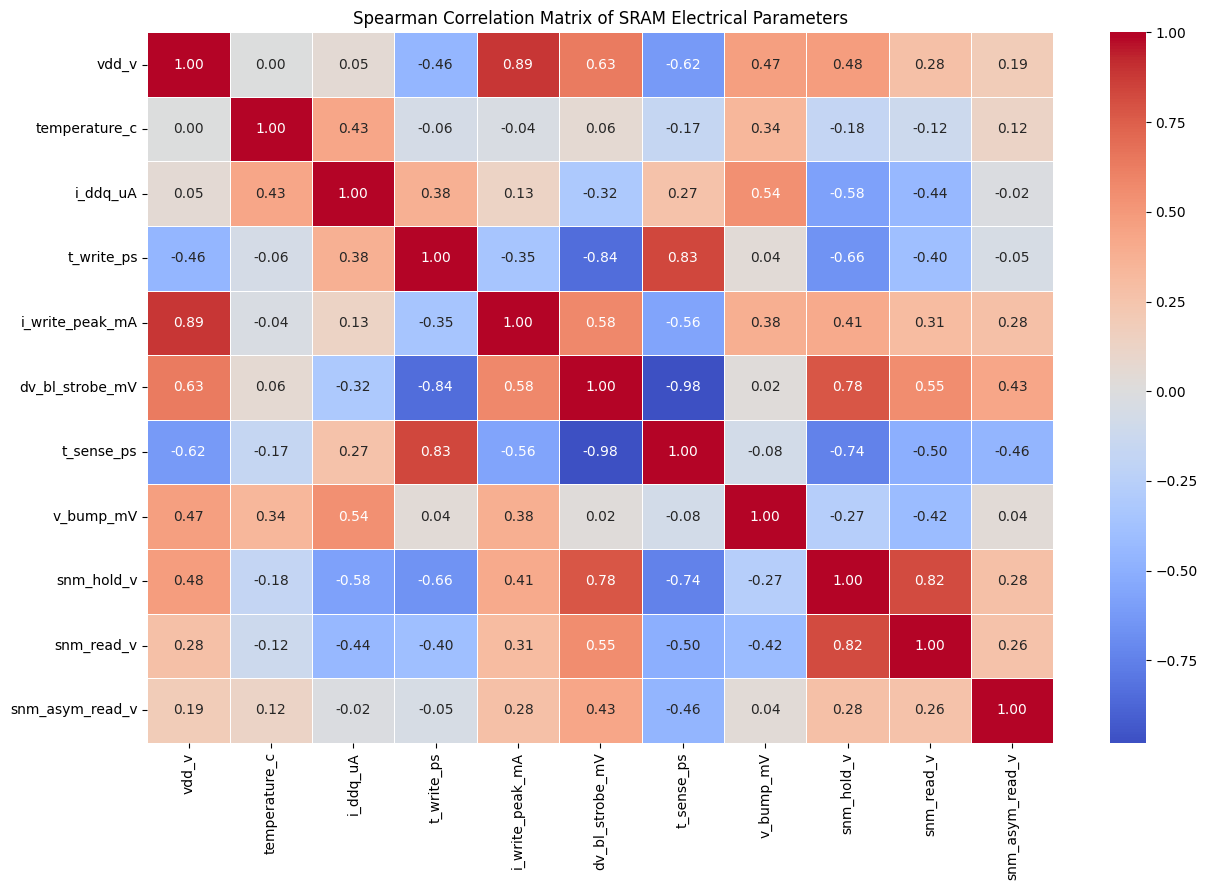

In [8]:
plt.figure(figsize=(13, 9))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Spearman Correlation Matrix of SRAM Electrical Parameters")
plt.tight_layout()
plt.show()

In [9]:
spearman_corr.to_csv(
    "../reports/sram_spearman_correlation.csv"
)

print("Correlation matrix saved successfully.")

Correlation matrix saved successfully.


In [10]:
from scipy.stats import kruskal

features_to_test = [
    "i_ddq_uA",
    "t_write_ps",
    "i_write_peak_mA",
    "dv_bl_strobe_mV",
    "t_sense_ps",
    "v_bump_mV",
    "snm_hold_v",
    "snm_read_v",
    "snm_asym_read_v"
]

results = []

for feature in features_to_test:

    groups = [
        group[feature].dropna().values
        for _, group in df.groupby("fault_class")
    ]

    statistic, p_value = kruskal(*groups)

    results.append({
        "Feature": feature,
        "H Statistic": statistic,
        "P Value": p_value
    })

kruskal_results = pd.DataFrame(results)

display(kruskal_results.round(6))

,Feature,H Statistic,P Value
0,i_ddq_uA,165.527519,0.000000
1,t_write_ps,227.952758,0.000000
2,i_write_peak_mA,22.974969,0.000128
3,dv_bl_strobe_mV,208.571363,0.000000
4,t_sense_ps,213.272656,0.000000
5,v_bump_mV,248.084076,0.000000
6,snm_hold_v,187.487344,0.000000
7,snm_read_v,176.844259,0.000000
8,snm_asym_read_v,271.538633,0.000000


In [1]:
%pip install scikit-posthocs


  Using cached statsmodels-0.15.0-cp310-cp310-win_amd64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached wrapt-2.5.2-cp310-cp310-win_amd64.whl.metadata (7.7 kB)
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
    --------------------------------------- 0.3/11.4 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.4 MB 730.2 kB/s eta 0:00:15
   - -------------------------------------- 0.5/11.4 MB 730.2 kB/s eta 0:00:15
   - -------------------------------------- 0.5/11.4 MB 730.2 kB/s eta 0:00:15
   -- ------------------------------------- 0.8/11.4 MB 559.5 kB/s eta 0:00:19
   -- ------------------------------------- 0.8/11.4

In [2]:
import scikit_posthocs as sp

features_to_test = [
    "i_ddq_uA",
    "t_write_ps",
    "i_write_peak_mA",
    "dv_bl_strobe_mV",
    "t_sense_ps",
    "v_bump_mV",
    "snm_hold_v",
    "snm_read_v",
    "snm_asym_read_v"
]

fault_labels = {
    0: "Healthy",
    1: "Resistive Open",
    2: "Bridging",
    3: "Storage Vth Drift",
    4: "Access Vth Drift"
}

for feature in features_to_test:

    print(f"\nDunn Test: {feature}")

    dunn_result = sp.posthoc_dunn(
        df,
        val_col=feature,
        group_col="fault_class",
        p_adjust="fdr_bh"
    )

    dunn_result.index = [
        fault_labels[int(x)] for x in dunn_result.index
    ]

    dunn_result.columns = [
        fault_labels[int(x)] for x in dunn_result.columns
    ]

    display(dunn_result.round(5))


Dunn Test: i_ddq_uA


NameError: name 'df' is not defined

In [4]:
import scikit_posthocs as sp
import pandas as pd
df = pd.read_csv("../data/raw/sram_fault_dataset.csv")
print(df["fault_class"].unique())
print(df["fault_class"].dtype)
print(df["fault_class"].value_counts())

[0 1 2 3 4]
int64
fault_class
1    180
4     90
3     90
2     75
0     15
Name: count, dtype: int64


In [5]:
import scikit_posthocs as sp

features_to_test = [
    "i_ddq_uA",
    "t_write_ps",
    "i_write_peak_mA",
    "dv_bl_strobe_mV",
    "t_sense_ps",
    "v_bump_mV",
    "snm_hold_v",
    "snm_read_v",
    "snm_asym_read_v"
]

fault_labels = {
    0: "Healthy",
    1: "Resistive Open",
    2: "Bridging",
    3: "Storage Vth Drift",
    4: "Access Vth Drift"
}

for feature in features_to_test:

    print(f"\nDunn Test: {feature}")

    dunn_result = sp.posthoc_dunn(
        df,
        val_col=feature,
        group_col="fault_class",
        p_adjust="fdr_bh"
    )

    dunn_result.index = [
        fault_labels[int(x)] for x in dunn_result.index
    ]

    dunn_result.columns = [
        fault_labels[int(x)] for x in dunn_result.columns
    ]

    display(dunn_result.round(5))


Dunn Test: i_ddq_uA


,Healthy,Resistive Open,Bridging,Storage Vth Drift,Access Vth Drift
Healthy,1.00000,0.92034,0.0,0.10843,0.92034
Resistive Open,0.92034,1.00000,0.0,0.00149,0.99524
Bridging,0.00000,0.00000,1.0,0.00000,0.00000
Storage Vth Drift,0.10843,0.00149,0.0,1.00000,0.00593
Access Vth Drift,0.92034,0.99524,0.0,0.00593,1.00000



Dunn Test: t_write_ps


,Healthy,Resistive Open,Bridging,Storage Vth Drift,Access Vth Drift
Healthy,1.00000,0.02429,0.0,0.79195,0.01394
Resistive Open,0.02429,1.00000,0.0,0.00000,0.52546
Bridging,0.00000,0.00000,1.0,0.00000,0.00000
Storage Vth Drift,0.79195,0.00000,0.0,1.00000,0.00000
Access Vth Drift,0.01394,0.52546,0.0,0.00000,1.00000



Dunn Test: i_write_peak_mA


,Healthy,Resistive Open,Bridging,Storage Vth Drift,Access Vth Drift
Healthy,1.00000,0.99606,0.78218,0.07425,0.74811
Resistive Open,0.99606,1.00000,0.73318,0.00003,0.34307
Bridging,0.78218,0.73318,1.00000,0.00710,0.78218
Storage Vth Drift,0.07425,0.00003,0.00710,1.00000,0.01350
Access Vth Drift,0.74811,0.34307,0.78218,0.01350,1.00000


... (8 outputs left out)


Dunn Test: snm_read_v


,Healthy,Resistive Open,Bridging,Storage Vth Drift,Access Vth Drift
Healthy,1.00000,0.98863,0.0,0.05214,0.25281
Resistive Open,0.98863,1.00000,0.0,0.00002,0.01196
Bridging,0.00000,0.00000,1.0,0.00000,0.00000
Storage Vth Drift,0.05214,0.00002,0.0,1.00000,0.00000
Access Vth Drift,0.25281,0.01196,0.0,0.00000,1.00000



Dunn Test: snm_asym_read_v


,Healthy,Resistive Open,Bridging,Storage Vth Drift,Access Vth Drift
Healthy,1.0,0.0,1.0,1.0,1.0
Resistive Open,0.0,1.0,0.0,0.0,0.0
Bridging,1.0,0.0,1.0,1.0,1.0
Storage Vth Drift,1.0,0.0,1.0,1.0,1.0
Access Vth Drift,1.0,0.0,1.0,1.0,1.0


In [6]:
import scikit_posthocs as sp
import pandas as pd

features_to_test = [
    "i_ddq_uA",
    "t_write_ps",
    "i_write_peak_mA",
    "dv_bl_strobe_mV",
    "t_sense_ps",
    "v_bump_mV",
    "snm_hold_v",
    "snm_read_v",
    "snm_asym_read_v"
]

fault_labels = {
    0: "Healthy",
    1: "Resistive Open",
    2: "Bridging",
    3: "Storage Vth Drift",
    4: "Access Vth Drift"
}

all_results = []

for feature in features_to_test:

    dunn_result = sp.posthoc_dunn(
        df,
        val_col=feature,
        group_col="fault_class",
        p_adjust="fdr_bh"
    )

    for i in dunn_result.index:
        for j in dunn_result.columns:

            # Keep each pair only once; exclude self-comparisons
            if int(i) < int(j):

                p_value = dunn_result.loc[i, j]

                all_results.append({
                    "Feature": feature,
                    "Class 1": fault_labels[int(i)],
                    "Class 2": fault_labels[int(j)],
                    "Adjusted P Value": p_value,
                    "Significant": p_value < 0.05
                })

dunn_summary = pd.DataFrame(all_results)

display(
    dunn_summary.sort_values(
        ["Feature", "Adjusted P Value"]
    ).round(6)
)

,Feature,Class 1,Class 2,Adjusted P Value,Significant
34,dv_bl_strobe_mV,Resistive Open,Bridging,0.000000,True
37,dv_bl_strobe_mV,Bridging,Storage Vth Drift,0.000000,True
38,dv_bl_strobe_mV,Bridging,Access Vth Drift,0.000000,True
31,dv_bl_strobe_mV,Healthy,Bridging,0.000000,True
36,dv_bl_strobe_mV,Resistive Open,Access Vth Drift,0.000025,True
...,...,...,...,...,...
56,v_bump_mV,Resistive Open,Access Vth Drift,0.000000,True
55,v_bump_mV,Resistive Open,Storage Vth Drift,0.003189,True
53,v_bump_mV,Healthy,Access Vth Drift,0.009698,True
52,v_bump_mV,Healthy,Storage Vth Drift,0.175415,False


In [7]:
dunn_summary.to_csv(
    "../reports/dunn_posthoc_results.csv",
    index=False
)

print("Dunn test results saved successfully!")

Dunn test results saved successfully!


In [8]:
feature_significance = (
    dunn_summary.groupby("Feature")["Significant"]
    .sum()
    .reset_index(name="Significant Comparisons")
    .sort_values("Significant Comparisons", ascending=False)
)

display(feature_significance)

,Feature,Significant Comparisons
7,t_write_ps,8
8,v_bump_mV,8
0,dv_bl_strobe_mV,7
5,snm_read_v,7
6,t_sense_ps,7
1,i_ddq_uA,6
3,snm_asym_read_v,4
4,snm_hold_v,4
2,i_write_peak_mA,3


In [9]:
summary_features = [
    "i_ddq_uA",
    "t_write_ps",
    "i_write_peak_mA",
    "dv_bl_strobe_mV",
    "t_sense_ps",
    "v_bump_mV",
    "snm_hold_v",
    "snm_read_v",
    "snm_asym_read_v"
]

class_summary = (
    df.groupby("fault_class")[summary_features]
    .agg(["median", "mean", "std"])
)

class_summary.index = class_summary.index.map(fault_labels)

display(class_summary.round(5))

i_ddq_uA                   t_write_ps               \
                    median     mean      std     median         mean   
fault_class                                                            
Healthy             0.0345  0.49924  1.00292      59.70     61.63333   
Resistive Open      0.0345  0.29053  0.48854      70.45     73.97944   
Bridging            4.8445  8.42862  9.93773   20000.00  20000.00000   
Storage Vth Drift   0.0065  0.13368  0.24132      59.25     60.85556   
Access Vth Drift    0.0345  0.33814  0.81404      70.30     74.48556   

                            i_write_peak_mA                   dv_bl_strobe_mV  \
                        std          median     mean      std          median   
fault_class                                                                     
Healthy             8.67720           0.035  0.03473  0.00861          227.70   
Resistive Open     18.08618           0.035  0.03469  0.00844          224.75   
Bridging            0.00000           0.033  0.03501  0.01205            0.00   
Storage Vth Drift   9.40875           0.028  0.02963  0.00926          214.15   
Access Vth Drift   15.81693           0.033  0.03341  0.00975          173.10   

                   ... v_bump_mV snm_hold_v                   snm_read_v  \
                   ...       std     median     mean      std     median   
fault_class        ...                                                     
Healthy            ...  25.31106    0.44890  0.44140  0.05287    0.23000   
Resistive Open     ...  24.53317    0.44890  0.44140  0.05122    0.23000   
Bridging           ...  31.45970    0.00000  0.00000  0.00000    0.00000   
Storage Vth Drift  ...  25.02136    0.43805  0.42942  0.07425    0.20680   
Access Vth Drift   ...  27.78051    0.44890  0.43660  0.06930    0.26515   

                                    snm_asym_read_v                   
                      mean      std          median    mean      std  
fault_class                                                           
Healthy            0.22476  0.07223          0.0000  0.0000  0.00000  
Resistive Open     0.22370  0.07191          0.0002  0.0008  0.00198  
Bridging           0.00000  0.00000          0.0000  0.0000  0.00000  
Storage Vth Drift  0.15393  0.10947          0.0000  0.0000  0.00000  
Access Vth Drift   0.23401  0.10410          0.0000  0.0000  0.00000  

[5 rows x 27 columns]

In [10]:
class_summary.to_csv(
    "../reports/fault_class_statistical_summary.csv"
)

print("Class-wise statistical summary saved!")

Class-wise statistical summary saved!


In [11]:
from itertools import combinations
from scipy.stats import mannwhitneyu
import numpy as np
import pandas as pd

effect_results = []

for feature in summary_features:
    for class1, class2 in combinations(sorted(df["fault_class"].unique()), 2):

        x = df.loc[df["fault_class"] == class1, feature].dropna()
        y = df.loc[df["fault_class"] == class2, feature].dropna()

        u_stat, p_value = mannwhitneyu(
            x, y, alternative="two-sided"
        )

        # Rank-biserial correlation
        effect_size = (2 * u_stat / (len(x) * len(y))) - 1

        effect_results.append({
            "Feature": feature,
            "Class 1": fault_labels[class1],
            "Class 2": fault_labels[class2],
            "Effect Size": effect_size,
            "Absolute Effect Size": abs(effect_size),
            "P Value": p_value
        })

effect_df = pd.DataFrame(effect_results)

display(
    effect_df.sort_values(
        "Absolute Effect Size", ascending=False
    ).round(4)
)

,Feature,Class 1,Class 2,Effect Size,Absolute Effect Size,P Value
14,t_write_ps,Resistive Open,Bridging,-1.0,1.0,0.0
11,t_write_ps,Healthy,Bridging,-1.0,1.0,0.0
18,t_write_ps,Bridging,Access Vth Drift,1.0,1.0,0.0
17,t_write_ps,Bridging,Storage Vth Drift,1.0,1.0,0.0
48,t_sense_ps,Bridging,Access Vth Drift,1.0,1.0,0.0
...,...,...,...,...,...,...
83,snm_asym_read_v,Healthy,Access Vth Drift,0.0,0.0,1.0
82,snm_asym_read_v,Healthy,Storage Vth Drift,0.0,0.0,1.0
87,snm_asym_read_v,Bridging,Storage Vth Drift,0.0,0.0,1.0
88,snm_asym_read_v,Bridging,Access Vth Drift,0.0,0.0,1.0


In [12]:
effect_df.to_csv(
    "../reports/effect_size_analysis.csv",
    index=False
)

In [13]:
print("Write delay capped at 20000 ps:")
print(df[df["t_write_ps"] >= 20000]["fault_class"].value_counts())

print("\nSense delay capped at 20000 ps:")
print(df[df["t_sense_ps"] >= 20000]["fault_class"].value_counts())

print("\nConvergence by fault class:")
print(pd.crosstab(df["fault_class"], df["converged"]))

Write delay capped at 20000 ps:
fault_class
2    75
Name: count, dtype: int64

Sense delay capped at 20000 ps:
fault_class
2    75
Name: count, dtype: int64

Convergence by fault class:
converged     0    1
fault_class         
0             3   12
1            21  159
2            75    0
3            33   57
4            16   74
